# 2 · Kubit, bramki i pomiar

**Koło Naukowe Qubit, PWr** · komputery bramkowe (Qiskit + IQM)

Wszystko działa na **symulatorze** na Twoim komputerze. Na końcu uruchomimy obwód na modelu
komputera IQM z szumem – takiego jak Odra 5 na PWr.

> 📚 Doczytaj: [IBM Quantum Learning – Basics of quantum information](https://quantum.cloud.ibm.com/learning/en/courses/basics-of-quantum-information), [IQM Academy](https://www.iqmacademy.com/).

In [1]:
# Tylko w Google Colab: instaluje potrzebne pakiety. Lokalnie ta komórka nic nie robi.
import sys
if "google.colab" in sys.modules:
    %pip install -q "iqm-client[qiskit]>=36,<37" "qiskit>=2.1,<2.2" qiskit-aer pylatexenc sympy


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector
from qiskit.visualization import plot_bloch_multivector, plot_histogram
from qiskit_aer import AerSimulator

sim = AerSimulator(seed_simulator=42)   # idealny (bezszumowy) symulator; seed = powtarzalne wyniki

## 1. Stan kubitu

Klasyczny bit to `0` albo `1`. Stan kubitu to wektor dwóch liczb zespolonych (amplitud):

$$|\psi\rangle = \alpha|0\rangle + \beta|1\rangle, \qquad |\alpha|^2 + |\beta|^2 = 1 .$$

Przy pomiarze dostajemy `0` z prawdopodobieństwem $|\alpha|^2$ i `1` z prawdopodobieństwem $|\beta|^2$.
Uwaga na popularne uproszczenie „kubit jest jednocześnie 0 i 1” – dokładniej: kubit jest w stanie opisanym
**amplitudami**, a dopiero pomiar daje jeden konkretny bit.

In [3]:
zero = Statevector.from_label("0")
plus = Statevector.from_label("+")      # (|0> + |1>)/sqrt(2)
print("|0> =", zero.data)
print("|+> =", np.round(plus.data, 3))
print("Prawdopodobieństwa pomiaru |+>:", plus.probabilities_dict())
plus.draw("latex")

|0> = [1.+0.j 0.+0.j]
|+> = [0.707+0.j 0.707+0.j]
Prawdopodobieństwa pomiaru |+>: {np.str_('0'): np.float64(0.4999999999999999), np.str_('1'): np.float64(0.4999999999999999)}


<IPython.core.display.Latex object>

## 2. Bramki i sfera Blocha

Każdy stan jednego kubitu (z dokładnością do nieistotnej fazy globalnej) to punkt na **sferze Blocha**:
biegun północny = $\lvert 0\rangle$, południowy = $\lvert 1\rangle$, równik = „równe szanse”.
Bramki to obroty tej sfery:

| bramka | co robi | na sferze |
|---|---|---|
| `X` | kwantowe NOT: $\lvert 0\rangle \leftrightarrow \lvert 1\rangle$ | obrót o 180° wokół osi X |
| `H` | Hadamard: $\lvert 0\rangle \to \lvert +\rangle$ | przenosi biegun na równik |
| `Z` | zmienia znak (fazę) przy $\lvert 1\rangle$ | obrót o 180° wokół osi Z |
| `RY(θ)` | obrót o kąt θ | płynnie od $\lvert 0\rangle$ do $\lvert 1\rangle$ |

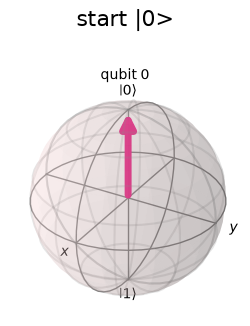

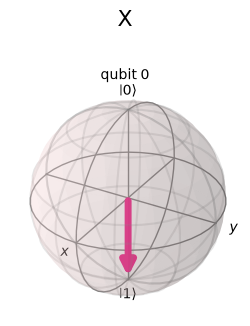

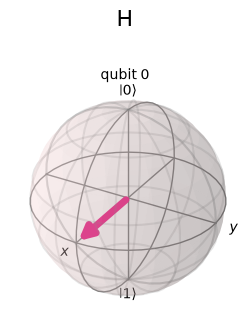

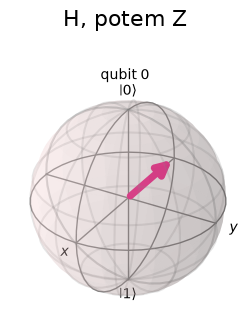

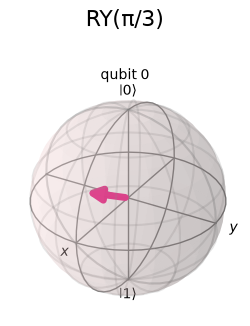

In [4]:
def state_after(*gates):
    """Buduje 1-kubitowy obwód z listy bramek (nazwy metod QuantumCircuit) i zwraca stan."""
    qc = QuantumCircuit(1)
    for g in gates:
        if isinstance(g, tuple):          # np. ("ry", np.pi/3)
            getattr(qc, g[0])(g[1], 0)
        else:
            getattr(qc, g)(0)
    return Statevector(qc)

examples = {
    "start |0>": [],
    "X": ["x"],
    "H": ["h"],
    "H, potem Z": ["h", "z"],
    "RY(π/3)": [("ry", np.pi / 3)],
}
for title, gates in examples.items():
    display(plot_bloch_multivector(state_after(*gates), title=title, figsize=(2.6, 2.6)))

## 3. Pomiar jest losowy – ale statystycznie przewidywalny

Obwód `H → pomiar` daje `0` albo `1` z prawdopodobieństwem 50%. Pojedynczy wynik jest losowy,
dlatego na komputerze kwantowym uruchamiamy obwód wiele razy (**shots**) i patrzymy na histogram.

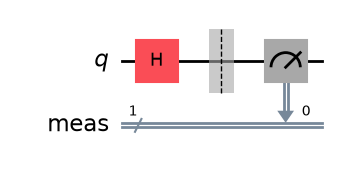

Pierwsze 20 pomiarów: 00011111100001010111


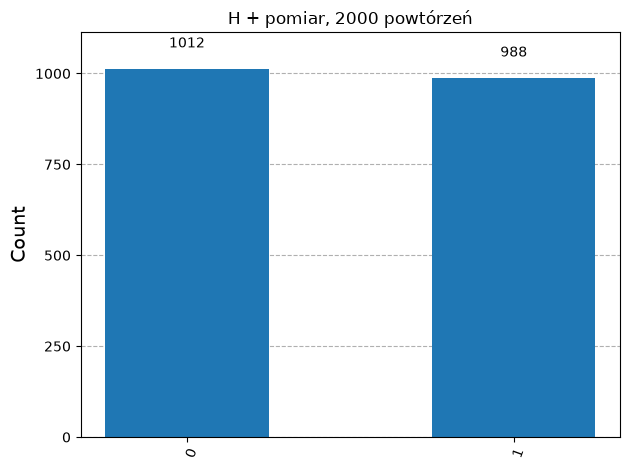

In [5]:
qc = QuantumCircuit(1)
qc.h(0)
qc.measure_all()
display(qc.draw("mpl"))

job = sim.run(transpile(qc, sim), shots=20, memory=True)
print("Pierwsze 20 pomiarów:", "".join(job.result().get_memory()))

counts = sim.run(transpile(qc, sim), shots=2000).result().get_counts()
plot_histogram(counts, title="H + pomiar, 2000 powtórzeń")

## 4. Odra 5 – komputer IQM na Politechnice Wrocławskiej

Od 2025 r. PWr ma własny komputer kwantowy **IQM Spark „Odra 5”** (5 kubitów nadprzewodzących, topologia **gwiazdy** –
jeden kubit centralny połączony z czterema pozostałymi), a także zdalny dostęp do większych maszyn IQM w Finlandii.
Najbliższym modelem w `iqm-client` jest `IQMFakeAdonis` – ta sama topologia gwiazdy (parametry szumu są przykładowe,
nie pochodzą z kalibracji Odry 5).
Uruchomimy na nim obwód na dwóch kubitach: bramka `H` na pierwszym kubicie, potem `CX`
(NOT sterowany pierwszym kubitem). W idealnym świecie wynik to zawsze `00` albo `11` (po ok. 50%) –
nigdy `01` ani `10`.


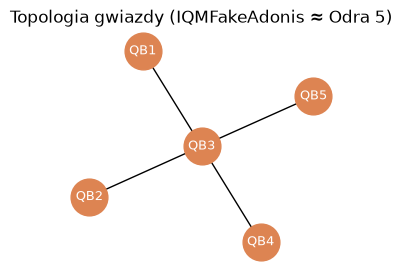

In [6]:
import networkx as nx
from iqm.qiskit_iqm import IQMFakeAdonis
adonis = IQMFakeAdonis()
star = nx.Graph([(adonis.index_to_qubit_name(a), adonis.index_to_qubit_name(b)) for a, b in adonis.coupling_map.get_edges()])
plt.figure(figsize=(3.5, 3))
nx.draw_networkx(star, nx.spring_layout(star, seed=1), node_color="#DD8452", node_size=700, font_color="white", font_size=9)
plt.title("Topologia gwiazdy (IQMFakeAdonis ≈ Odra 5)"); plt.axis("off"); plt.show()

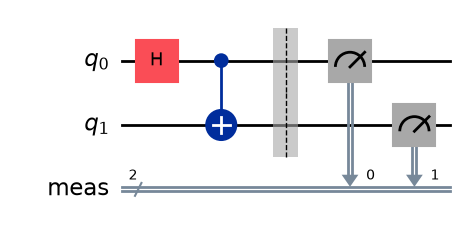

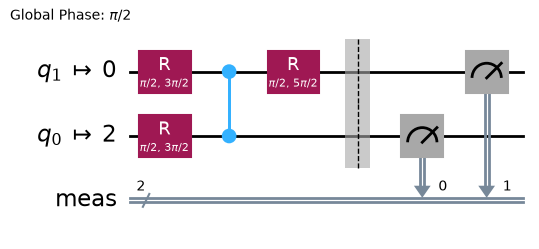

In [7]:
# H na kubicie 0, potem CX (kubit 0 steruje kubitem 1) – idealnie tylko 00 albo 11
qc = QuantumCircuit(2)
qc.h(0)
qc.cx(0, 1)
qc.measure_all()
display(qc.draw("mpl"))

# Ten sam obwód przepisany na bramki i kubity procesora IQM (bramki r i cz)
tqc = transpile(qc, adonis, seed_transpiler=1)
display(tqc.draw("mpl", idle_wires=False))


idealny symulator:    {'00': 983, '11': 1017}
IQMFakeAdonis (szum): {'00': 923, '01': 92, '10': 84, '11': 901}
Wyniki 01 i 10 (niemożliwe w idealnym obwodzie): 176 z 2000 = 8.8%


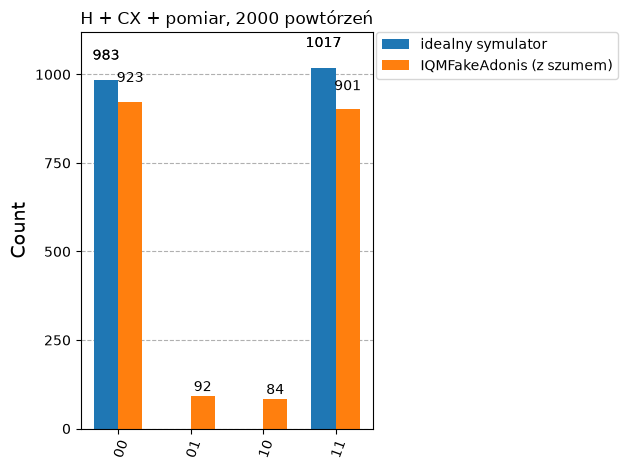

In [8]:
counts_ideal = sim.run(transpile(qc, sim), shots=2000).result().get_counts()
counts_odra = adonis.run(tqc, shots=2000, seed_simulator=7).result().get_counts()
print("idealny symulator:   ", dict(sorted(counts_ideal.items())))
print("IQMFakeAdonis (szum):", dict(sorted(counts_odra.items())))

bledne = counts_odra.get("01", 0) + counts_odra.get("10", 0)
print(f"Wyniki 01 i 10 (niemożliwe w idealnym obwodzie): {bledne} z 2000 = {bledne / 2000:.1%}")

plot_histogram([counts_ideal, counts_odra], legend=["idealny symulator", "IQMFakeAdonis (z szumem)"],
               title="H + CX + pomiar, 2000 powtórzeń")


Na modelu z szumem pojawiają się też wyniki `01` i `10`, których idealny obwód nigdy nie daje. To skutek szumu:
odczyt kubitu czasem się myli (w tym modelu w ok. 2–6% przypadków, zależnie od kubitu), a bramka dwukubitowa `cz`,
na którą kompilator zamienia `CX`, ma błąd rzędu kilku procent. Na prawdziwym komputerze dzieje się to samo –
dlatego obwód uruchamiamy wiele razy i patrzymy na statystykę.
